# Laboratory Activity: Titanic Decision Tree

**Time Limit:** 2 Hours  
**Platform:** Google Colab  
**Dataset:** `titanic.csv`  
**Algorithm:** Decision Tree Classification

## Scenario
You are given passenger records from the Titanic. Your task is to build a **Decision Tree** that predicts whether a passenger **Survived (1)** or **Did Not Survive (0)**.

This laboratory is intentionally less guided. You already know the basic Python workflow from class. Your job is to decide what commands you need and demonstrate that you understand the model—not just run code.

## Rules
- Write your own Python code in the blank code cells.
- You may add additional code/Markdown cells.
- Keep your outputs visible.
- Explain your results in your own words.
-### Internet access is allowed **only for Google Colab and Microsoft Teams**.

**Not allowed:** Google/search engines, YouTube, external websites, ChatGPT, Gemini, Copilot, or other AI tools.

Complete the activity using only the **provided files and concepts discussed in class**.



# PART 1 — Import and Explore the Dataset


1. Upload `titanic.csv` to Google Colab.
2. Import the necessary Python library/libraries.
3. Read the CSV file into a DataFrame.
4. Display the dataset.
5. Determine:
   - Number of rows and columns
   - Column names
   - Data types
   - Missing values
6. Briefly describe what you notice about the dataset.

### Questions
**1. What does one row represent?**  
Answer: One row represents the singular passenger in the dataset.

**2. What is the target variable?**  
Answer: The target variable is survived.

**3. Is this classification or regression? Why?**  
Answer: Classification since regression refers to guessing a specific number. Classifications just specifies a certain feature to a given categories.

**4. Which columns do you think may help predict survival?**  
Answer: Passenger Class, Sex, Age

**5. Are there columns/records that may need attention before model training? Explain.**  
Answer: Yes, the sex must be translated into numerical form before it is fed to the model and some entries must be removed if it contains any missing information. This will invalidate the dataset since there are missing data.


In [250]:
import pandas as pd

df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
0,1,0,3,male,22.0,1,0,7.2500
1,2,1,1,female,38.0,1,0,71.2833
2,3,1,3,female,26.0,0,0,7.9250
3,4,1,1,female,35.0,1,0,53.1000
4,5,0,3,male,35.0,0,0,8.0500


In [251]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  100 non-null    int64  
 1   Survived     100 non-null    int64  
 2   Pclass       100 non-null    int64  
 3   Sex          100 non-null    str    
 4   Age          78 non-null     float64
 5   SibSp        100 non-null    int64  
 6   Parch        100 non-null    int64  
 7   Fare         100 non-null    float64
dtypes: float64(2), int64(5), str(1)
memory usage: 6.4 KB


In [252]:
df.isna().sum()

PassengerId     0
Survived        0
Pclass          0
Sex             0
Age            22
SibSp           0
Parch           0
Fare            0
dtype: int64

# PART 2 — Prepare the Data


Prepare the dataset so it can be used by your Decision Tree.

### Requirements
- Use **`Survived`** as the target.
- Use these features:
  - `Pclass`
  - `Sex`
  - `Age`
  - `SibSp`
  - `Parch`
  - `Fare`
- Convert `Sex` into a numerical form.
- For this activity, **remove rows that contain missing values in the selected features.**
- Separate your data into **X (features)** and **y (target)**.
- Show evidence that your prepared dataset contains no missing values.

### Questions
**1. How many records remained after cleaning?**  
Answer: 78.

**2. Why does `Sex` need to be converted before using it in this model?**  
Answer: The decision tree can only process numbers and not strings.

**3. What is X? What is y?**  
Answer: X are the features that aims to predict the target, which is y.


In [253]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df = df.dropna()
df.isna().sum()
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]
y = df['Survived']

# PART 3 — Build the Decision Tree


Build a **Decision Tree Classifier**.

### Requirements
- Split the dataset into **training data and testing data**.
- Use **80% for training** and **20% for testing**.
- Use `random_state=42`.
- Use **Gini Impurity**.
- Set `max_depth=3`.
- Train the model using the training data.
- Make predictions using the testing data.
- Display both:
  - Training accuracy
  - Testing accuracy



In [254]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 62
Testing samples: 16


In [255]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

print(model)

DecisionTreeClassifier(max_depth=3, random_state=42)


In [256]:
model.fit(X_train, y_train)
print("Training complete!")

Training complete!


In [257]:
y_pred = model.predict(X_test)
target_names = {0: "Did not survive", 1:"Survived"}
comparison = pd.DataFrame({
    "Actual": [target_names[i] for i in y_test],
    "Predicted": [target_names[i] for i in y_pred]
})

comparison.head(10)

,Actual,Predicted
0,Survived,Survived
1,Survived,Survived
2,Survived,Survived
3,Did not survive,Did not survive
4,Did not survive,Did not survive
5,Did not survive,Did not survive
6,Did not survive,Did not survive
7,Survived,Did not survive
8,Did not survive,Did not survive
9,Survived,Did not survive


In [258]:
score = model.score(X_train, y_train)

print("Score:", round(score, 3))
print("Score Percentage:", round(score * 100, 2), "%")

Score: 0.903
Score Percentage: 90.32 %


In [259]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.688
Accuracy Percentage: 68.75 %


In [260]:
from sklearn.metrics import confusion_matrix

classes = ["Did Not Survive", "Survived"]

cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=classes,
    columns=classes
)

cm_df

,Did Not Survive,Survived
Did Not Survive,7,3
Survived,2,4


In [261]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=classes
))

                 precision    recall  f1-score   support

Did Not Survive       0.78      0.70      0.74        10
       Survived       0.57      0.67      0.62         6

       accuracy                           0.69        16
      macro avg       0.67      0.68      0.68        16
   weighted avg       0.70      0.69      0.69        16



# PART 4 — Evaluate Your Predictions


Evaluate your model using:

- **Confusion Matrix**
- **Classification Report**

### Questions
Questions
1. Based on the Confusion Matrix, how many predictions did your model get correct?


Answer: 11 predictions were correct.

2. How many predictions did your model get wrong?


Answer: 5 predictions were wrong.

3. Look at the Classification Report. What is the F1-score for passengers who Survived?

Answer: 62% is the F1 score of those who survived.

4. Based on the F1-score, how would you describe your model's ability to identify passengers who survived?

Answer: My model has an F1-score of 62%. This means that model has a moderate or fair level of predictive performance, balancing both precision and recall.

5. Compare the F1-score of Survived and Did Not Survive. Which class did your model identify more successfully?

Answer: Did Not Survive is the class the model was able to identify more successfully.

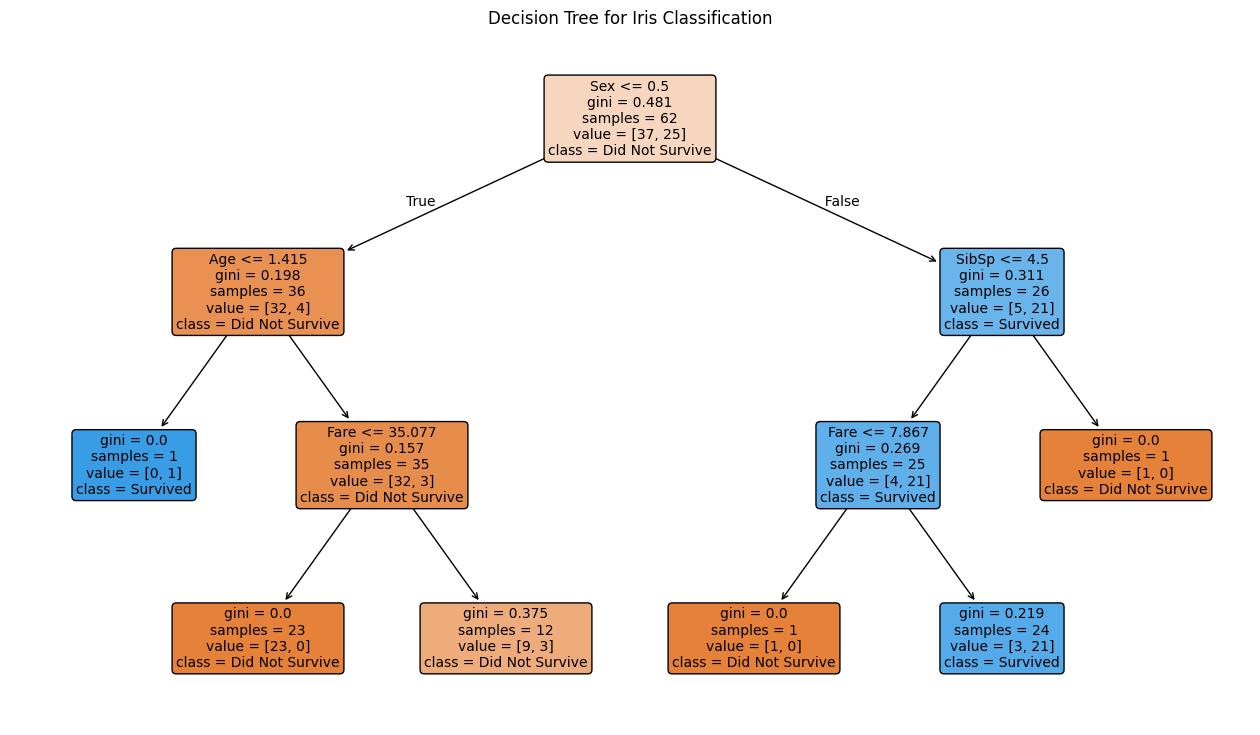

In [262]:
from sklearn.tree import plot_tree
from matplotlib import pyplot as plt

plt.figure(figsize=(16, 9))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=classes,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Iris Classification")
plt.show()

# PART 5 — Visualize and Interpret the Tree


Visualize your trained Decision Tree. Make sure the visualization shows the:

- Feature names
- Class names
- Gini Impurity
- Number of samples
- Values/classes
- Branches and leaves

Then **read the tree instead of simply showing it.**

### Tree Detective Questions
**1. What feature became the root node?**  
Answer: Sex.

**2. What exact question/condition does the root ask?**  
Answer: Is the sex of the passenger male?

**3. What is the Gini Impurity at the root?**  
Answer: 0.481

**4. Find one node with a lower Gini value. Why is its Gini lower?**  
Answer: There is one node with a 0.0 Gini value. Its Gini is lower because there is only one sample. The value of Gini is determined by the purity of its sample.

**5. Find one leaf with `gini = 0`, if one exists. What does `gini = 0` mean?**  
Answer: There are two leafs with `gini = 0`. This means that they are pure, meaning there are no mixed classes in the group.


# PART 6 — Overfitting Challenge 🌲
### Suggested Time: 15 minutes

Your current tree uses `max_depth=3`.

Now create **one additional Decision Tree with no `max_depth` limit**.

Compare the two models.

| Model | Training Accuracy | Testing Accuracy |
|---|---:|---:|
| `max_depth=3` |90.32%|68.75% |
| No depth limit |100%|81.25%|

### Questions

**1. Did allowing the tree to grow freely automatically create a better model? Explain using your results.**  
Answer: Yes, since it allowed the model to ask more questions that made the model more accurate.

**2. Do you see evidence of possible overfitting? Why or why not?**  
Answer: No, since the model actually needed more information which requires more data by asking more question.


In [263]:
overfit_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

print(model)

DecisionTreeClassifier(max_depth=3, random_state=42)


In [264]:
overfit_model.fit(X_train, y_train)
print("Training complete!")

Training complete!


In [265]:
y_pred = overfit_model.predict(X_test)
target_names = {0: "Did not survive", 1:"Survived"}
comparison = pd.DataFrame({
    "Actual": [target_names[i] for i in y_test],
    "Predicted": [target_names[i] for i in y_pred]
})

comparison.head(10)

,Actual,Predicted
0,Survived,Survived
1,Survived,Survived
2,Survived,Survived
3,Did not survive,Did not survive
4,Did not survive,Did not survive
5,Did not survive,Did not survive
6,Did not survive,Did not survive
7,Survived,Did not survive
8,Did not survive,Did not survive
9,Survived,Did not survive


In [268]:
score = overfit_model.score(X_train, y_train)

print("Score:", round(score, 3))
print("Score Percentage:", round(score * 100, 2), "%")

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Score: 1.0
Score Percentage: 100.0 %
Accuracy: 0.812
Accuracy Percentage: 81.25 %


#  FINAL CHALLENGE — Introduce a New Passenger!

Your Decision Tree has been trained and tested. Now it is time to give it a passenger it has **never seen before**.

Create a **fictional Titanic passenger** and let your trained Decision Tree predict whether the passenger will:

**SURVIVE (1)** or **NOT SURVIVE (0)**




In [267]:
toni_fowler = pd.DataFrame([{
    'Pclass': 1,
    'Sex': 1,
    'Age': 35,
    'SibSp': 4,
    'Parch': 0,
    'Fare': 150
}])
prediction = model.predict(toni_fowler)[0]

print("Prediction:", classes[prediction])

Prediction: Survived


After completing the New Passenger Challenge, imagine that you are explaining your work to someone who has **never studied Machine Learning before**.

Using your new passenger as your example, explain:
> "A Decision Tree works by asking a set of learned questions that lead to a decision. This is similar to human decision-making breaking down the dataset into smaller, more specific subsets. This is similar to Pinoy Henyo where the other player just answers yes-or-no and the other person just keeps asking question that narrows it down to the specific feature to guess.
>
> For my passenger, the first question was asking if the passenger is male or female. In this case, the passenger is female.
>
> Based on the passenger's information, the model followed the next question where it asked if the passenger has siblings or parents. The passenger has 4 siblings or parents.
>
> It continued asking if the passenger's fare was less than 7.87. In this case, the passenger has more than that which was 150.
>
> Finally, the passenger reached a leaf node that predicted that the passenger survived.
>
> Therefore, I learned that a Decision Tree is basically a giant akinator game that tries to guess the targeted feature of a specific data based on its other characteristics, which it achieves by answering yes-or-no that corresponds to the characteristics."

//pwedeng fill in the blanks or make the sentence as a whole

# Grading Criteria — 100 Points

| Criteria | Points |
|---|---:|
| Dataset Exploration & Understanding | 10 |
| Data Preparation | 15 |
| Decision Tree Implementation | 20 |
| Model Evaluation & F1-Score Interpretation | 15 |
| Tree Visualization & Interpretation | 20 |
| Overfitting Challenge | 10 |
| New Passenger Challenge & Final Explanation | 10 |
| **TOTAL** | **100** |